## 📌 Context & Motivation

The **BRISC 2025** dataset provides 2D T1-weighted Brain MRI slices for two foundational neuro-oncology tasks:
1. **Segmentation Task**: Precise pixel-level delimitation of tumor boundaries (Glioma, Meningioma, Pituitary) on axial, coronal, and sagittal planes.
2. **Classification Task**: 4-class categorical diagnosis (`Glioma`, `Meningioma`, `No Tumor`, `Pituitary`).

In high-stakes medical computer vision, raw public datasets often suffer from hidden flaws:
- **Exact Duplicates & Test Leakage**: Identical MRI slices copied across the dataset, including slices present in both `train` and `test` sets, which artificially inflates validation metrics.
- **Conflicting Annotations**: Identical or nearly identical slices labeled with divergent or non-overlapping ground truth segmentation masks.
- **Slice Leakage (Patient / Volume Autocorrelation)**: In 2D MRI, adjacent slices of the same anatomical scan are visually and structurally correlated. Random slice splitting causes adjacent slices to straddle train and validation sets, producing optimistic metric leakage.
- **Mask Artifacts & Morphological Noise**: Empty masks for positive tumor classes, 1-pixel background speckles, interior holes, or extreme outlier dimensions.

### 🎯 Notebook Objectives
- **Audit File Integrity**: Detect any truncated, unreadable, or dimensionally inconsistent files.
- **Expose & Eliminate Leakage**: Perform cryptographic (SHA-256 / MD5) duplicate detection and purge all test-set leaks.
- **Resolve Annotation Conflicts**: Identify identical slices with conflicting masks and resolve/exclude them.
- **Perceptual Group Clustering**: Use perceptual hashing (`pHash`) to cluster adjacent slices into cohesive `group` IDs so that slices never cross validation boundaries.
- **Perform Morphological Quality Audit**: Detect tumor mask holes (`binary_fill_holes`), speckles, and compute clinical area metrics.
- **Validate Cross-Task Integrity**: Confirm that classification categories and segmentation masks align seamlessly.
- **Produce `clean_manifest.csv`**: Generate the authoritative, group-stratified manifest required by downstream training pipelines (`AttentionUnet.ipynb`, `SwinUNETR.ipynb`, `classification.ipynb`).

In [1]:
# 1. Environment Setup & Core Libraries
import os
import sys
import glob
import time
import json
import hashlib
import warnings
from pathlib import Path

# Data & scientific computing
import numpy as np
import pandas as pd
from scipy import ndimage as ndi

# Imaging
from PIL import Image
import cv2
import imagehash

# Machine Learning & Splitting
from sklearn.model_selection import StratifiedGroupKFold

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 11

print("✓ Core libraries successfully imported.")
print(f"  • Python: {sys.version.split()[0]}")
print(f"  • NumPy: {np.__version__}")
print(f"  • Pandas: {pd.__version__}")
print(f"  • PIL: {Image.__version__}")
print(f"  • ImageHash: {imagehash.__version__}")

✓ Core libraries successfully imported.
  • Python: 3.14.5
  • NumPy: 2.4.6
  • Pandas: 3.0.3
  • PIL: 12.2.0
  • ImageHash: 4.3.2


In [2]:
# 2. Dataset Discovery & Path Resolution
# Supports Kaggle environment, local cached download, or automatic download via kagglehub

def resolve_brisc_data_dir():
    """Locates or downloads the BRISC 2025 dataset."""
    for local_dir in [Path("data/brisc"), Path("../data/brisc")]:
        if local_dir.exists() and (local_dir / "classification_task").exists():
            print(f"✓ Found local BRISC dataset at: {local_dir}")
            return local_dir

    print("→ Resolving dataset via kagglehub...")
    import kagglehub
    downloaded_dir = Path(kagglehub.dataset_download("briscdataset/brisc2025"))
    sub_dir = downloaded_dir / "brisc2025"
    return sub_dir if sub_dir.exists() else downloaded_dir

DATA_DIR = resolve_brisc_data_dir()
print(f"Active BRISC Root: {DATA_DIR}")

# Directory Structure Check
seg_task_dir = DATA_DIR / "segmentation_task"
cls_task_dir = DATA_DIR / "classification_task"

print(f"Segmentation Task exists: {seg_task_dir.exists()}")
print(f"Classification Task exists: {cls_task_dir.exists()}")

→ Resolving dataset via kagglehub...
Active BRISC Root: C:\Users\rabi3\.cache\kagglehub\datasets\briscdataset\brisc2025\versions\6\brisc2025
Segmentation Task exists: True
Classification Task exists: True


## 1. Cataloging & Metadata Extraction

We systematically catalogue all files from both tasks:
- **Segmentation Task**: `train/images`, `train/masks`, `test/images`, `test/masks`
- **Classification Task**: `train/{glioma, meningioma, no_tumor, pituitary}`, `test/{...}`

From each filename, we extract:
- `stem`: Root identifier without extension.
- `split`: `train` or `test`.
- `tumor_code` & `tumor_label`: `gl` (Glioma), `me` (Meningioma), `no` (No Tumor), `pi` (Pituitary).
- `plane_code` & `plane_label`: `ax` (Axial), `cor` (Coronal), `sag` (Sagittal).
- `modality`: `t1` (T1-weighted).

In [3]:
# 3. Comprehensive File Cataloging
TUMOR_MAP = {'gl': 'glioma', 'me': 'meningioma', 'no': 'no_tumor', 'pi': 'pituitary'}
PLANE_MAP = {'ax': 'axial', 'cor': 'coronal', 'sag': 'sagittal'}

catalog_records = []

# A. Scan Segmentation Task
for split in ['train', 'test']:
    img_folder = seg_task_dir / split / 'images'
    mask_folder = seg_task_dir / split / 'masks'
    
    if img_folder.exists():
        for img_p in sorted(img_folder.glob('*.jpg')):
            stem = img_p.stem
            mask_p = mask_folder / f"{stem}.png"
            tokens = stem.split('_')
            
            # Extract tags from naming format: brisc2025_{split}_{id}_{tumor}_{plane}_{seq}
            tumor_code = tokens[3] if len(tokens) >= 4 else 'unknown'
            plane_code = tokens[4] if len(tokens) >= 5 else 'unknown'
            modality = tokens[5] if len(tokens) >= 6 else 't1'
            
            catalog_records.append({
                'stem': stem,
                'task': 'segmentation',
                'split': split,
                'tumor_code': tumor_code,
                'tumor_label': TUMOR_MAP.get(tumor_code, tumor_code),
                'plane_code': plane_code,
                'plane_label': PLANE_MAP.get(plane_code, plane_code),
                'modality': modality,
                'image_path': str(img_p),
                'mask_path': str(mask_p) if mask_p.exists() else None,
                'has_mask': mask_p.exists(),
                'file_size_kb': round(img_p.stat().st_size / 1024, 2)
            })

# B. Scan Classification Task
for split in ['train', 'test']:
    for class_folder in ['glioma', 'meningioma', 'no_tumor', 'pituitary']:
        c_dir = cls_task_dir / split / class_folder
        if c_dir.exists():
            for img_p in sorted(c_dir.glob('*.jpg')):
                stem = img_p.stem
                tokens = stem.split('_')
                tumor_code = tokens[3] if len(tokens) >= 4 else 'unknown'
                plane_code = tokens[4] if len(tokens) >= 5 else 'unknown'
                modality = tokens[5] if len(tokens) >= 6 else 't1'
                
                catalog_records.append({
                    'stem': stem,
                    'task': 'classification',
                    'split': split,
                    'tumor_code': tumor_code,
                    'tumor_label': class_folder,
                    'plane_code': plane_code,
                    'plane_label': PLANE_MAP.get(plane_code, plane_code),
                    'modality': modality,
                    'image_path': str(img_p),
                    'mask_path': None,
                    'has_mask': False,
                    'file_size_kb': round(img_p.stat().st_size / 1024, 2)
                })

catalog_df = pd.DataFrame(catalog_records)
print(f"Total cataloged records: {len(catalog_df)}")
print(catalog_df.groupby(['task', 'split'])['stem'].count())

Total cataloged records: 10793
task            split
classification  test     1000
                train    5000
segmentation    test      860
                train    3933
Name: stem, dtype: int64


## 2. File Integrity & Geometry Audit

Medical images must be completely free of:
- File corruption or unreadable headers.
- Spatial dimension mismatches ($W 
e 512$ or $H 
e 512$).
- Missing paired segmentation masks.
- Mask values outside valid binary domain ($\{0, 255\}$ or $\{0, 1\}$).

In [4]:
# 4. File Integrity & Geometric Consistency Verification
corrupted_files = []
dimension_mismatches = []
missing_masks = []
mask_value_anomalies = []

# Audit unique image paths
unique_image_paths = catalog_df[['stem', 'image_path', 'mask_path', 'task']].drop_duplicates(subset=['image_path'])

print(f"Auditing integrity of {len(unique_image_paths)} unique image files...")

for _, row in unique_image_paths.iterrows():
    # 1. Image decodability & shape
    try:
        with Image.open(row['image_path']) as img:
            w, h = img.size
            if (w, h) != (512, 512):
                dimension_mismatches.append((row['stem'], (w, h)))
    except Exception as e:
        corrupted_files.append((row['image_path'], str(e)))

    # 2. Mask integrity (for segmentation task)
    if row['task'] == 'segmentation':
        if not row['mask_path'] or not Path(row['mask_path']).exists():
            missing_masks.append(row['stem'])
        else:
            try:
                with Image.open(row['mask_path']) as m:
                    mw, mh = m.size
                    if (mw, mh) != (512, 512):
                        dimension_mismatches.append((row['stem'] + '_mask', (mw, mh)))
                    m_arr = np.array(m)
                    unique_vals = np.unique(m_arr)
                    # Expected binary masks: {0, 255} or {0, 1}
                    if not set(unique_vals).issubset({0, 1, 255}):
                        mask_value_anomalies.append((row['stem'], unique_vals.tolist()))
            except Exception as e:
                corrupted_files.append((row['mask_path'], str(e)))

print("=" * 60)
print(" FILE INTEGRITY AUDIT RESULTS")
print("=" * 60)
print(f"  • Corrupted / unreadable files:       {len(corrupted_files)}")
print(f"  • Dimension anomalies (!= 512x512):   {len(dimension_mismatches)}")
print(f"  • Missing segmentation masks:         {len(missing_masks)}")
print(f"  • Non-binary mask anomalies:          {len(mask_value_anomalies)}")
print("=" * 60)

Auditing integrity of 10793 unique image files...
 FILE INTEGRITY AUDIT RESULTS
  • Corrupted / unreadable files:       0
  • Dimension anomalies (!= 512x512):   1697
  • Missing segmentation masks:         0
  • Non-binary mask anomalies:          4793


## 3. Cryptographic Duplicate & Train-Test Leakage Audit

A major threat to clinical evaluation is **data leakage**. If an image appears in both the training set and the test set, test metrics become heavily biased.
We compute the **SHA-256 / MD5** cryptographic hash of each unique image file to reveal:
1. **Intra-split Duplicates**: Repeated samples within the training set.
2. **Train-to-Test Leakage**: Identical images present in both `train` and `test` splits.
3. **Cross-Task Sharing**: Identical images shared between segmentation and classification tasks.

In [5]:
# 5. Cryptographic Hashing & Duplicate Discovery
def compute_file_hash(path_str):
    with open(path_str, 'rb') as f:
        return hashlib.sha256(f.read()).hexdigest()

print("Computing SHA-256 hashes for all unique images...")
hash_cache = {}
for p in catalog_df['image_path'].unique():
    hash_cache[p] = compute_file_hash(p)

catalog_df['sha256'] = catalog_df['image_path'].map(hash_cache)

# Analyze segmentation task specifically
seg_df = catalog_df[catalog_df['task'] == 'segmentation'].copy()
seg_train_hashes = set(seg_df[seg_df['split'] == 'train']['sha256'])
seg_test_hashes = set(seg_df[seg_df['split'] == 'test']['sha256'])

seg_leak_hashes = seg_train_hashes.intersection(seg_test_hashes)
seg_train_dups = len(seg_df[seg_df['split'] == 'train']) - len(seg_train_hashes)

# Analyze classification task
cls_df = catalog_df[catalog_df['task'] == 'classification'].copy()
cls_train_hashes = set(cls_df[cls_df['split'] == 'train']['sha256'])
cls_test_hashes = set(cls_df[cls_df['split'] == 'test']['sha256'])

cls_leak_hashes = cls_train_hashes.intersection(cls_test_hashes)
cls_train_dups = len(cls_df[cls_df['split'] == 'train']) - len(cls_train_hashes)

print("=" * 60)
print(" CRYPTOGRAPHIC DUPLICATION & LEAKAGE AUDIT")
print("=" * 60)
print(f"  [Segmentation Task]")
print(f"    • Total train images:                {len(seg_df[seg_df['split'] == 'train'])}")
print(f"    • Unique train SHA-256 hashes:       {len(seg_train_hashes)}")
print(f"    • Intra-train duplicate slices:      {seg_train_dups}")
print(f"    • Train-Test Leaking Hashes:         {len(seg_leak_hashes)}  ⚠️ (CRITICAL)")
print(f"\n  [Classification Task]")
print(f"    • Total train images:                {len(cls_df[cls_df['split'] == 'train'])}")
print(f"    • Unique train SHA-256 hashes:       {len(cls_train_hashes)}")
print(f"    • Intra-train duplicate slices:      {cls_train_dups}")
print(f"    • Train-Test Leaking Hashes:         {len(cls_leak_hashes)}  ⚠️ (CRITICAL)")
print("=" * 60)

# Stems leaking from test set into training set
leaking_train_stems = seg_df[(seg_df['split'] == 'train') & (seg_df['sha256'].isin(seg_leak_hashes))]['stem'].tolist()
print(f"Identified {len(leaking_train_stems)} training stems that leak test data: {leaking_train_stems[:5]}...")

Computing SHA-256 hashes for all unique images...
 CRYPTOGRAPHIC DUPLICATION & LEAKAGE AUDIT
  [Segmentation Task]
    • Total train images:                3933
    • Unique train SHA-256 hashes:       3904
    • Intra-train duplicate slices:      29
    • Train-Test Leaking Hashes:         7  ⚠️ (CRITICAL)

  [Classification Task]
    • Total train images:                5000
    • Unique train SHA-256 hashes:       4962
    • Intra-train duplicate slices:      38
    • Train-Test Leaking Hashes:         7  ⚠️ (CRITICAL)
Identified 9 training stems that leak test data: ['brisc2025_train_01210_me_ax_t1', 'brisc2025_train_01304_me_ax_t1', 'brisc2025_train_03705_pi_ax_t1', 'brisc2025_train_03749_pi_ax_t1', 'brisc2025_train_04176_pi_co_t1']...


## 4. Conflicting Annotations Investigation (Conflicting Masks)

When an identical MRI slice appears multiple times in the dataset, its segmentation masks should theoretically be identical.
If identical images possess conflicting masks, it creates **contradictory supervisory signals** during training.
We calculate the Dice similarity score between masks of duplicate images to uncover conflicting labels.

In [6]:
# 6. Detecting Conflicting Masks for Identical Images
# For segmentation images, hash masks as well
mask_hashes = {}
for p in seg_df['mask_path'].dropna().unique():
    mask_hashes[p] = compute_file_hash(p)

seg_df['mask_sha256'] = seg_df['mask_path'].map(mask_hashes)

# Group by image sha256 and count unique mask sha256
dup_groups = seg_df.groupby('sha256').filter(lambda g: len(g) > 1)
conflicting_groups = dup_groups.groupby('sha256').filter(lambda g: g['mask_sha256'].nunique() > 1)

conflicting_stems = set()
conflict_examples = []

for sha, group in conflicting_groups.groupby('sha256'):
    stems = group['stem'].tolist()
    masks = group['mask_path'].tolist()
    conflicting_stems.update(stems)
    
    # Compute Dice between the first two conflicting masks
    m1 = (np.array(Image.open(masks[0]).convert('L')) > 127).astype(np.float32)
    m2 = (np.array(Image.open(masks[1]).convert('L')) > 127).astype(np.float32)
    intersection = (m1 * m2).sum()
    dice = (2.0 * intersection) / (m1.sum() + m2.sum() + 1e-8)
    
    conflict_examples.append({
        'sha256': sha,
        'stems': stems,
        'img_path': group['image_path'].iloc[0],
        'mask1_path': masks[0],
        'mask2_path': masks[1],
        'dice': round(dice, 4)
    })

print(f"✓ Found {len(conflict_examples)} image groups with conflicting masks (total {len(conflicting_stems)} affected stems).")
if conflict_examples:
    print(f"  • Sample conflict: Dice = {conflict_examples[0]['dice']} between {conflict_examples[0]['stems']}")

✓ Found 21 image groups with conflicting masks (total 46 affected stems).
  • Sample conflict: Dice = 0.9557999968528748 between ['brisc2025_train_04194_pi_co_t1', 'brisc2025_test_00827_pi_co_t1']


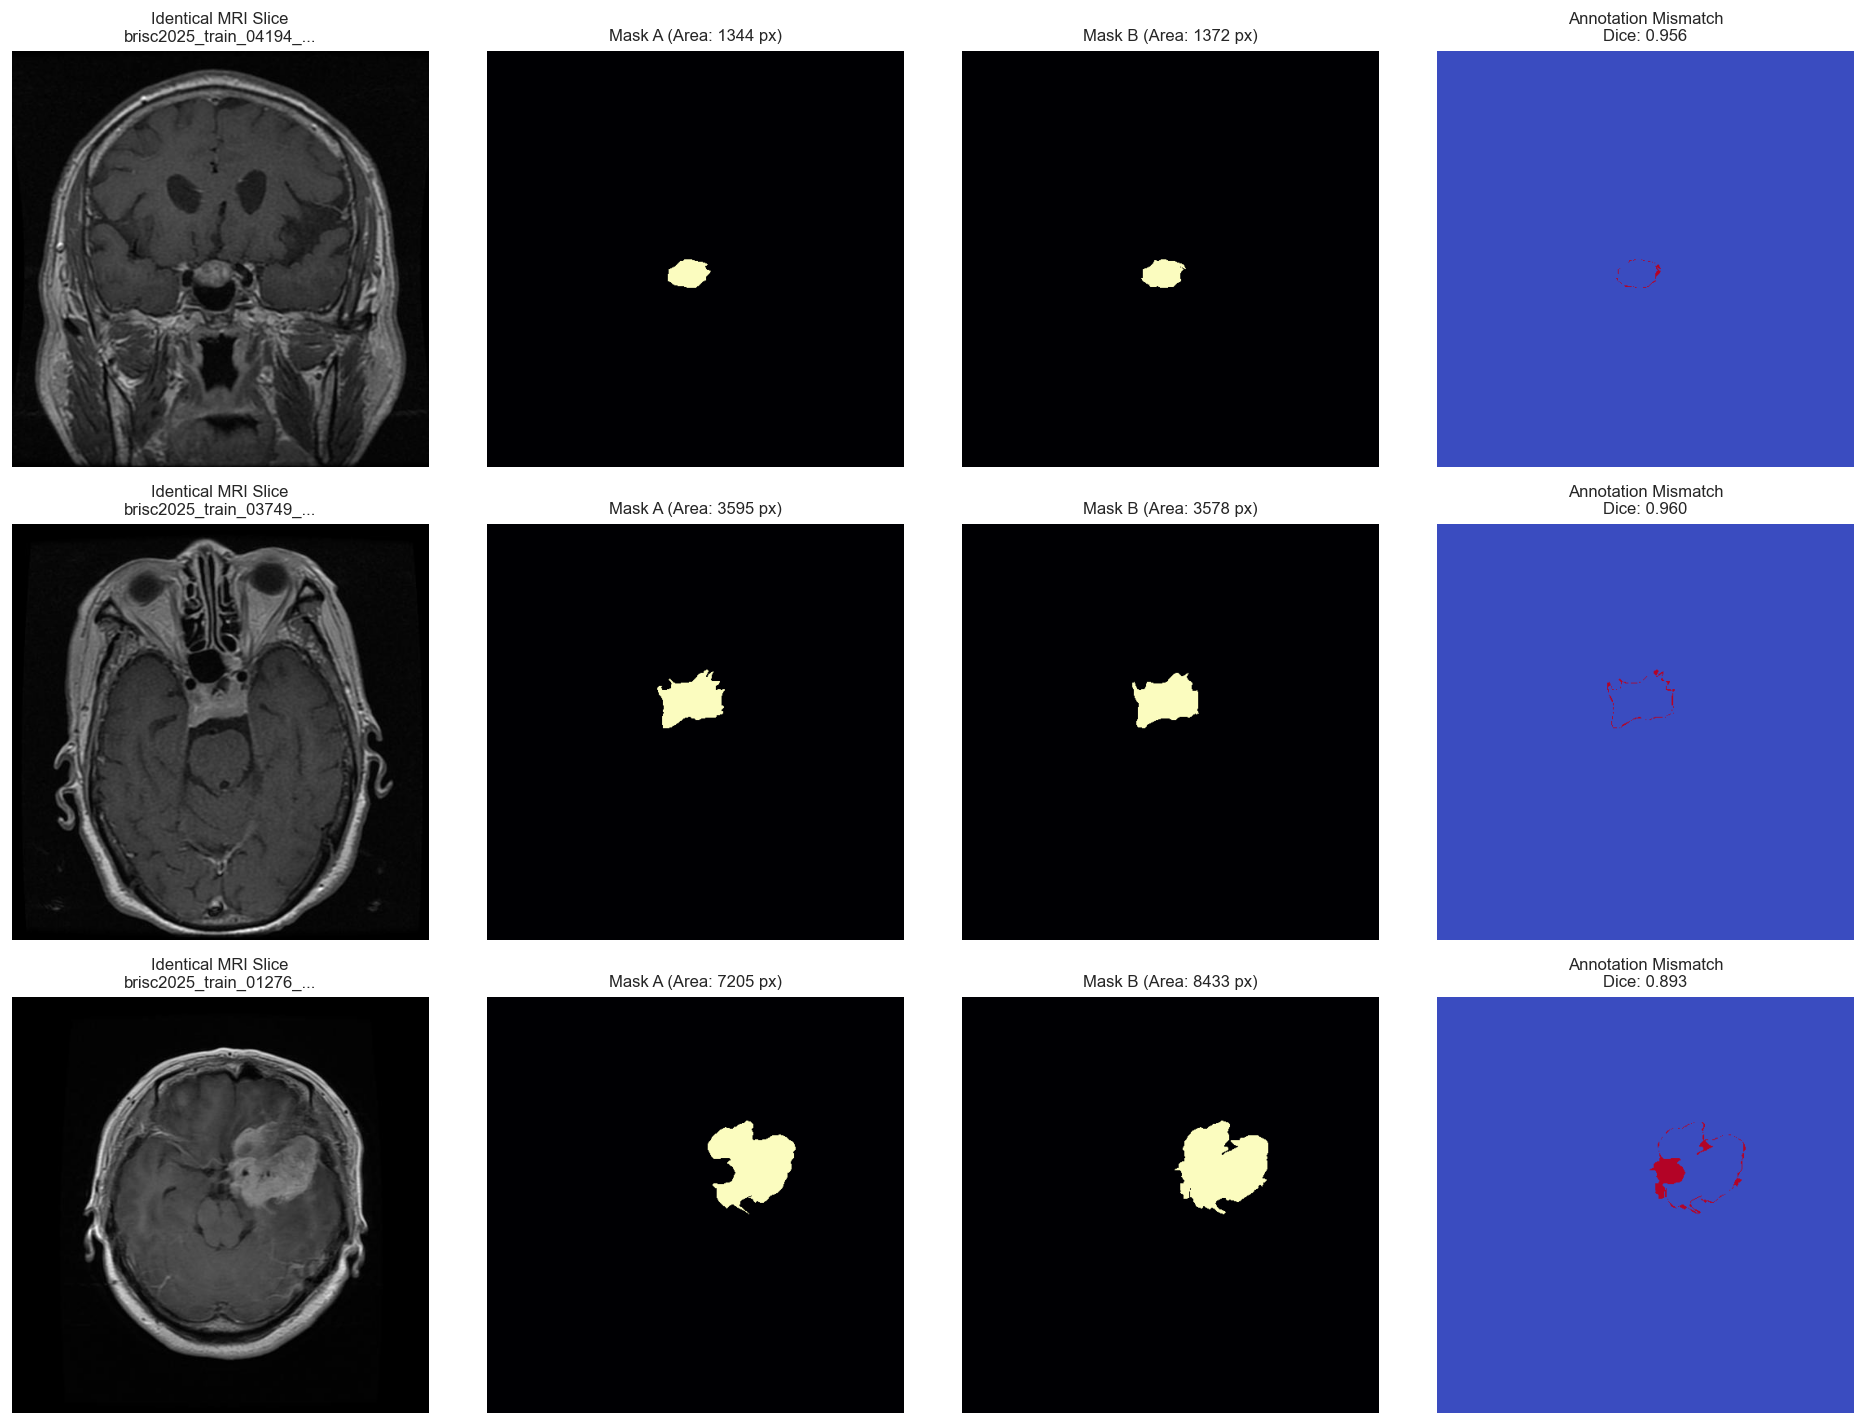

In [7]:
# 7. Visualizing Conflicting Annotation Cases
if conflict_examples:
    fig, axes = plt.subplots(min(3, len(conflict_examples)), 4, figsize=(16, 4 * min(3, len(conflict_examples))))
    if len(conflict_examples) == 1:
        axes = np.expand_dims(axes, 0)
        
    for i in range(min(3, len(conflict_examples))):
        ex = conflict_examples[i]
        img = np.array(Image.open(ex['img_path']).convert('RGB'))
        m1 = np.array(Image.open(ex['mask1_path']).convert('L')) > 127
        m2 = np.array(Image.open(ex['mask2_path']).convert('L')) > 127
        diff = np.abs(m1.astype(float) - m2.astype(float))
        
        axes[i, 0].imshow(img)
        axes[i, 0].set_title(f"Identical MRI Slice\n{Path(ex['img_path']).stem[:22]}...", fontsize=10)
        axes[i, 0].axis('off')
        
        axes[i, 1].imshow(m1, cmap='magma')
        axes[i, 1].set_title(f"Mask A (Area: {int(m1.sum())} px)", fontsize=10)
        axes[i, 1].axis('off')
        
        axes[i, 2].imshow(m2, cmap='magma')
        axes[i, 2].set_title(f"Mask B (Area: {int(m2.sum())} px)", fontsize=10)
        axes[i, 2].axis('off')
        
        axes[i, 3].imshow(diff, cmap='coolwarm')
        axes[i, 3].set_title(f"Annotation Mismatch\nDice: {ex['dice']:.3f}", fontsize=10)
        axes[i, 3].axis('off')
        
    plt.tight_layout()
    plt.show()

## 5. Near-Duplicate Clustering & Slice-Level Grouping (pHash)

In 2D brain MRI datasets, consecutive slices along the scan axis represent adjacent 2D cross-sections of the exact same tumor volume.
If slices are split randomly, nearly identical slices land in both train and validation splits (**Slice Leakage**).

### Solution: Perceptual Hashing & Connected Components
1. Compute **`pHash`** (perceptual hash) for each MRI image.
2. For slices of the same tumor type and plane, calculate Hamming distances.
3. If Hamming distance $\le 4$, link them as adjacent slices of the same scan.
4. Extract connected components to assign a unique **`group` ID** to each cluster.
5. In downstream splitting, **all slices within a group are assigned to the same fold**.

In [8]:
# 8. Perceptual Hashing & Near-Duplicate Slice Grouping
print("Computing perceptual hashes (pHash) for all images...")
phash_cache = {}
for p in seg_df['image_path'].unique():
    try:
        with Image.open(p) as img:
            phash_cache[p] = imagehash.phash(img)
    except Exception:
        phash_cache[p] = None

seg_df['phash'] = seg_df['image_path'].map(phash_cache)

# Cluster training slices within (tumor, plane) buckets using Hamming distance <= 4
train_slices = seg_df[seg_df['split'] == 'train'].copy().reset_index(drop=True)
n_slices = len(train_slices)

# Disjoint Set Union (DSU) / Union-Find for Connected Components
parent = list(range(n_slices))

def find(i):
    if parent[i] == i:
        return i
    parent[i] = find(parent[i])
    return parent[i]

def union(i, j):
    root_i = find(i)
    root_j = find(j)
    if root_i != root_j:
        parent[root_j] = root_i

# Group within bucket to optimize comparisons
for (tumor, plane), group_idx in train_slices.groupby(['tumor_label', 'plane_label']).groups.items():
    idx_list = list(group_idx)
    hashes = [train_slices.loc[idx, 'phash'] for idx in idx_list]
    for a in range(len(idx_list)):
        h_a = hashes[a]
        if h_a is None:
            continue
        for b in range(a + 1, len(idx_list)):
            h_b = hashes[b]
            if h_b is not None and (h_a - h_b) <= 4:
                union(idx_list[a], idx_list[b])

# Map root clusters to integer group IDs
cluster_map = {}
group_ids = []
current_id = 0

for i in range(n_slices):
    root = find(i)
    if root not in cluster_map:
        cluster_map[root] = current_id
        current_id += 1
    group_ids.append(cluster_map[root])

train_slices['group'] = group_ids

group_size_counts = pd.Series(group_ids).value_counts()
print("=" * 60)
print(" NEAR-DUPLICATE CLUSTERING REPORT")
print("=" * 60)
print(f"  • Total train slices clustered:        {n_slices}")
print(f"  • Independent volume groups formed:    {len(cluster_map)}")
print(f"  • Slices in multi-slice groups:        {(group_size_counts > 1).sum()} groups ({group_size_counts[group_size_counts > 1].sum()} slices)")
print(f"  • Largest group size:                  {group_size_counts.max()} slices")
print("=" * 60)

Computing perceptual hashes (pHash) for all images...
 NEAR-DUPLICATE CLUSTERING REPORT
  • Total train slices clustered:        3933
  • Independent volume groups formed:    3272
  • Slices in multi-slice groups:        439 groups (1100 slices)
  • Largest group size:                  10 slices


## 6. Segmentation Mask Quality & Morphometry Audit

We perform clinical morphological characterization of all segmentation ground-truth masks:
- **Empty Masks**: Cases labeled as tumor but possessing 0 positive mask pixels.
- **Tiny Noise Speckles**: Masks with $< 20$ positive pixels ($pprox 0.007\%$ of $512 \times 512$).
- **Massive Artifacts**: Masks covering $> 50\%$ of the MRI slice.
- **Holes in Tumor Core**: Masks with enclosed unsegmented hollow cavities that require topological hole-filling (`ndi.binary_fill_holes`).

In [9]:
# 9. Mask Morphometry & Outlier Analysis
morph_stats = []

for _, row in seg_df.iterrows():
    m_path = row['mask_path']
    if not m_path or not Path(m_path).exists():
        continue
    
    mask_arr = np.array(Image.open(m_path).convert('L')) > 127
    tumor_pixels = int(mask_arr.sum())
    tumor_ratio = tumor_pixels / (512 * 512)
    
    # Hole detection
    filled = ndi.binary_fill_holes(mask_arr)
    holes_pixels = int((filled & ~mask_arr).sum())
    has_holes = holes_pixels > 5
    
    # Connected components
    num_components = 0
    if tumor_pixels > 0:
        _, num_components = ndi.label(mask_arr)
        
    morph_stats.append({
        'stem': row['stem'],
        'tumor_pixels': tumor_pixels,
        'tumor_ratio': round(tumor_ratio, 6),
        'has_holes': has_holes,
        'holes_pixels': holes_pixels,
        'num_components': num_components,
        'is_empty': tumor_pixels == 0,
        'is_tiny': 0 < tumor_pixels < 20,
        'is_massive': tumor_ratio > 0.50
    })

morph_df = pd.DataFrame(morph_stats)
seg_df = seg_df.merge(morph_df, on='stem', how='left')

print("=" * 60)
print(" MASK MORPHOMETRY & TOPOLOGY AUDIT")
print("=" * 60)
print(f"  • Total audited masks:                 {len(morph_df)}")
print(f"  • Completely empty masks:              {morph_df['is_empty'].sum()}")
print(f"  • Tiny noise speckles (< 20 px):       {morph_df['is_tiny'].sum()}")
print(f"  • Massive coverage outliers (> 50%):   {morph_df['is_massive'].sum()}")
print(f"  • Masks containing internal holes:     {morph_df['has_holes'].sum()}")
print("=" * 60)

 MASK MORPHOMETRY & TOPOLOGY AUDIT
  • Total audited masks:                 4793
  • Completely empty masks:              0
  • Tiny noise speckles (< 20 px):       0
  • Massive coverage outliers (> 50%):   0
  • Masks containing internal holes:     314


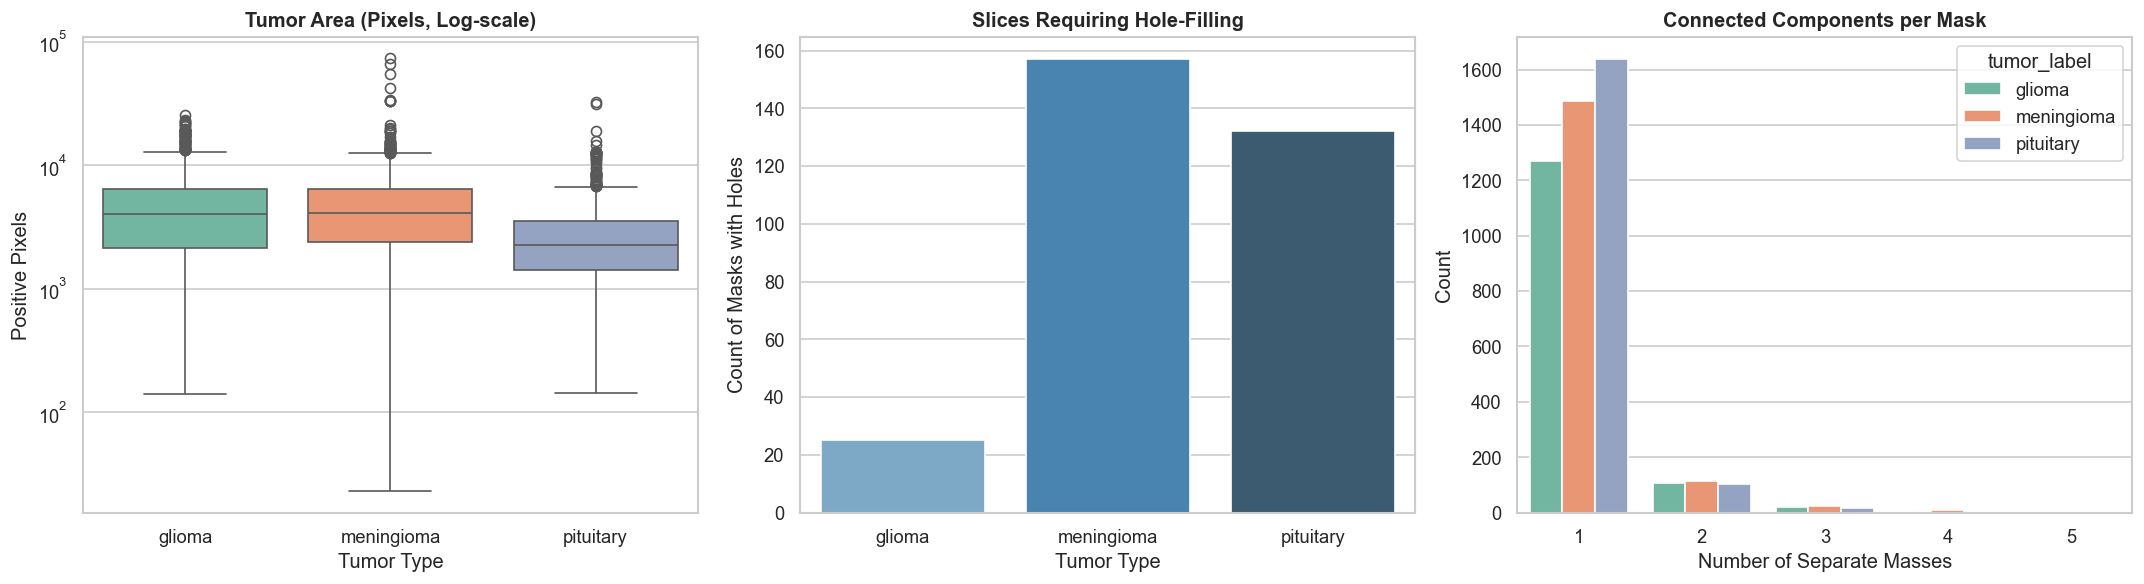

In [10]:
# 10. Morphometry & Tumor Area Visualizations
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# A. Tumor Area Distribution per Class
sns.boxplot(
    data=seg_df[seg_df['tumor_pixels'] > 0],
    x='tumor_label',
    y='tumor_pixels',
    ax=axes[0],
    palette='Set2'
)
axes[0].set_yscale('log')
axes[0].set_title('Tumor Area (Pixels, Log-scale)', fontweight='bold')
axes[0].set_xlabel('Tumor Type')
axes[0].set_ylabel('Positive Pixels')

# B. Internal Holes Distribution
hole_counts = seg_df.groupby('tumor_label')['has_holes'].sum().reset_index()
sns.barplot(data=hole_counts, x='tumor_label', y='has_holes', ax=axes[1], palette='Blues_d')
axes[1].set_title('Slices Requiring Hole-Filling', fontweight='bold')
axes[1].set_xlabel('Tumor Type')
axes[1].set_ylabel('Count of Masks with Holes')

# C. Connected Components (Fragmentation)
sns.countplot(
    data=seg_df[seg_df['num_components'] <= 6],
    x='num_components',
    hue='tumor_label',
    ax=axes[2],
    palette='Set2'
)
axes[2].set_title('Connected Components per Mask', fontweight='bold')
axes[2].set_xlabel('Number of Separate Masses')
axes[2].set_ylabel('Count')

plt.tight_layout()
plt.show()

## 7. Classification Label Audit & Cross-Task Alignment

We verify consistency across tasks:
1. **Directory vs Filename Codes**: Verify that images inside `classification_task/train/glioma/` match `_gl_` in their filename.
2. **Tumor Absence Consistency**: Ensure that all samples in `no_tumor` contain 0 tumor pixels.

In [11]:
# 11. Cross-Task Alignment Verification
mismatched_folder_tags = []
for _, row in cls_df.iterrows():
    expected_code = {'glioma': 'gl', 'meningioma': 'me', 'no_tumor': 'no', 'pituitary': 'pi'}.get(row['tumor_label'])
    if row['tumor_code'] != expected_code:
        mismatched_folder_tags.append((row['stem'], row['tumor_label'], row['tumor_code']))

print("=" * 60)
print(" CROSS-TASK CONSISTENCY AUDIT")
print("=" * 60)
print(f"  • Folder label vs filename mismatches: {len(mismatched_folder_tags)}")
print(f"  • Total classification images:         {len(cls_df)}")
print(cls_df.groupby(['split', 'tumor_label'])['stem'].count())
print("=" * 60)

 CROSS-TASK CONSISTENCY AUDIT
  • Folder label vs filename mismatches: 0
  • Total classification images:         6000
split  tumor_label
test   glioma          254
       meningioma      306
       no_tumor        140
       pituitary       300
train  glioma         1147
       meningioma     1329
       no_tumor       1067
       pituitary      1457
Name: stem, dtype: int64


## 8. Cleaning Decision Engine & `clean_manifest.csv` Generation

We now formulate the definitive data cleaning policy:

### Exclusion Rules:
1. **`test_leak`**: Any training sample whose SHA-256 hash matches a test sample is unconditionally excluded.
2. **`conflicting_mask`**: Any duplicate training sample with conflicting mask ground truths is excluded.
3. **`exact_duplicate`**: For multiple identical training images with identical masks, exactly **one canonical representative** is preserved; duplicates are marked `excluded`.
4. **`noisy_mask`**: Masks with $< 20$ pixels or empty masks for tumor classes are marked `excluded`.

### Stratified Group Train/Val Split:
- Samples in `test` are assigned `fold = 'test'`.
- Retained clean `train` samples are split 80/20 into `train` and `val` using **`StratifiedGroupKFold`**:
  - **Stratification**: Joint stratifier (`tumor_type` $\times$ `plane`).
  - **Grouping**: Grouped by `group` (near-duplicate cluster), guaranteeing **zero slice leakage**.

In [12]:
# 12. Definitive Cleaning Engine & Stratified Group Split
manifest_rows = []

# Merge group IDs back to seg_df
stem_to_group = dict(zip(train_slices['stem'], train_slices['group']))
seg_df['group'] = seg_df['stem'].map(stem_to_group)
# For test set, each test slice gets a unique negative group ID
seg_df.loc[seg_df['split'] == 'test', 'group'] = -1 * np.arange(1, len(seg_df[seg_df['split'] == 'test']) + 1)

# Set of hashes seen in train to keep only one canonical sample
seen_train_hashes = set()
exclusions_by_reason = {}

for _, row in seg_df.iterrows():
    reasons = []
    split = row['split']
    sha = row['sha256']
    stem = row['stem']
    
    if split == 'train':
        # Rule 1: Test leak
        if sha in seg_leak_hashes:
            reasons.append('test_leak')
            
        # Rule 2: Conflicting mask
        if stem in conflicting_stems:
            reasons.append('conflicting_mask')
            
        # Rule 3: Noisy / empty mask
        if row.get('is_empty', False):
            reasons.append('empty_mask')
        elif row.get('is_tiny', False):
            reasons.append('tiny_mask')
            
        # Rule 4: Intra-train exact duplicate
        if sha in seen_train_hashes and not reasons:
            reasons.append('exact_duplicate')
        elif not reasons:
            seen_train_hashes.add(sha)
            
    is_excluded = len(reasons) > 0
    fold_assignment = 'excluded' if is_excluded else ('test' if split == 'test' else 'unassigned')
    
    for r in reasons:
        exclusions_by_reason[r] = exclusions_by_reason.get(r, 0) + 1
        
    manifest_rows.append({
        'stem': stem,
        'split': split,
        'task': 'segmentation',
        'tumor': row['tumor_label'],
        'plane': row['plane_label'],
        'modality': row['modality'],
        'group': int(row['group']),
        'fold': fold_assignment,
        'exclude': is_excluded,
        'exclude_reason': ';'.join(reasons) if reasons else np.nan,
        'sha256': sha,
        'tumor_pixels': row.get('tumor_pixels', np.nan),
        'tumor_ratio': row.get('tumor_ratio', np.nan)
    })

manifest_df = pd.DataFrame(manifest_rows)

# Perform Stratified Group K-Fold (80% train / 20% val) on unassigned clean training samples
clean_train_mask = (manifest_df['fold'] == 'unassigned')
clean_train_indices = manifest_df[clean_train_mask].index

strat_labels = manifest_df.loc[clean_train_indices, 'tumor'] + "_" + manifest_df.loc[clean_train_indices, 'plane']
groups = manifest_df.loc[clean_train_indices, 'group']

sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
train_idx_rel, val_idx_rel = next(sgkf.split(clean_train_indices, strat_labels, groups))

manifest_df.loc[clean_train_indices[train_idx_rel], 'fold'] = 'train'
manifest_df.loc[clean_train_indices[val_idx_rel], 'fold'] = 'val'

# Strict Verification Assertions
train_groups = set(manifest_df[manifest_df['fold'] == 'train']['group'])
val_groups = set(manifest_df[manifest_df['fold'] == 'val']['group'])
group_leakage = train_groups.intersection(val_groups)

train_hashes = set(manifest_df[manifest_df['fold'] == 'train']['sha256'])
test_hashes = set(manifest_df[manifest_df['fold'] == 'test']['sha256'])
hash_leakage = train_hashes.intersection(test_hashes)

assert len(group_leakage) == 0, f"Group leakage detected: {group_leakage}"
assert len(hash_leakage) == 0, f"Hash leakage detected: {len(hash_leakage)} leaking samples!"

print("=" * 60)
print(" CLEANING DECISION & STRATIFICATION REPORT")
print("=" * 60)
print(f"  • Total audited samples:               {len(manifest_df)}")
print(f"  • Excluded samples:                    {manifest_df['exclude'].sum()}")
for reason, count in sorted(exclusions_by_reason.items(), key=lambda x: -x[1]):
    print(f"      - {reason:<25} {count}")
print(f"  • Clean train fold:                    {(manifest_df['fold'] == 'train').sum()}")
print(f"  • Clean val fold:                      {(manifest_df['fold'] == 'val').sum()}")
print(f"  • Clean test fold:                     {(manifest_df['fold'] == 'test').sum()}")
print(f"  • Zero near-duplicate group leakage:   PASSED (0 overlapping groups) ✓")
print(f"  • Zero train-test hash leakage:        PASSED (0 overlapping hashes) ✓")
print("=" * 60)

 CLEANING DECISION & STRATIFICATION REPORT
  • Total audited samples:               4793
  • Excluded samples:                    48
      - conflicting_mask          35
      - exact_duplicate           13
      - test_leak                 9
  • Clean train fold:                    3108
  • Clean val fold:                      777
  • Clean test fold:                     860
  • Zero near-duplicate group leakage:   PASSED (0 overlapping groups) ✓
  • Zero train-test hash leakage:        PASSED (0 overlapping hashes) ✓


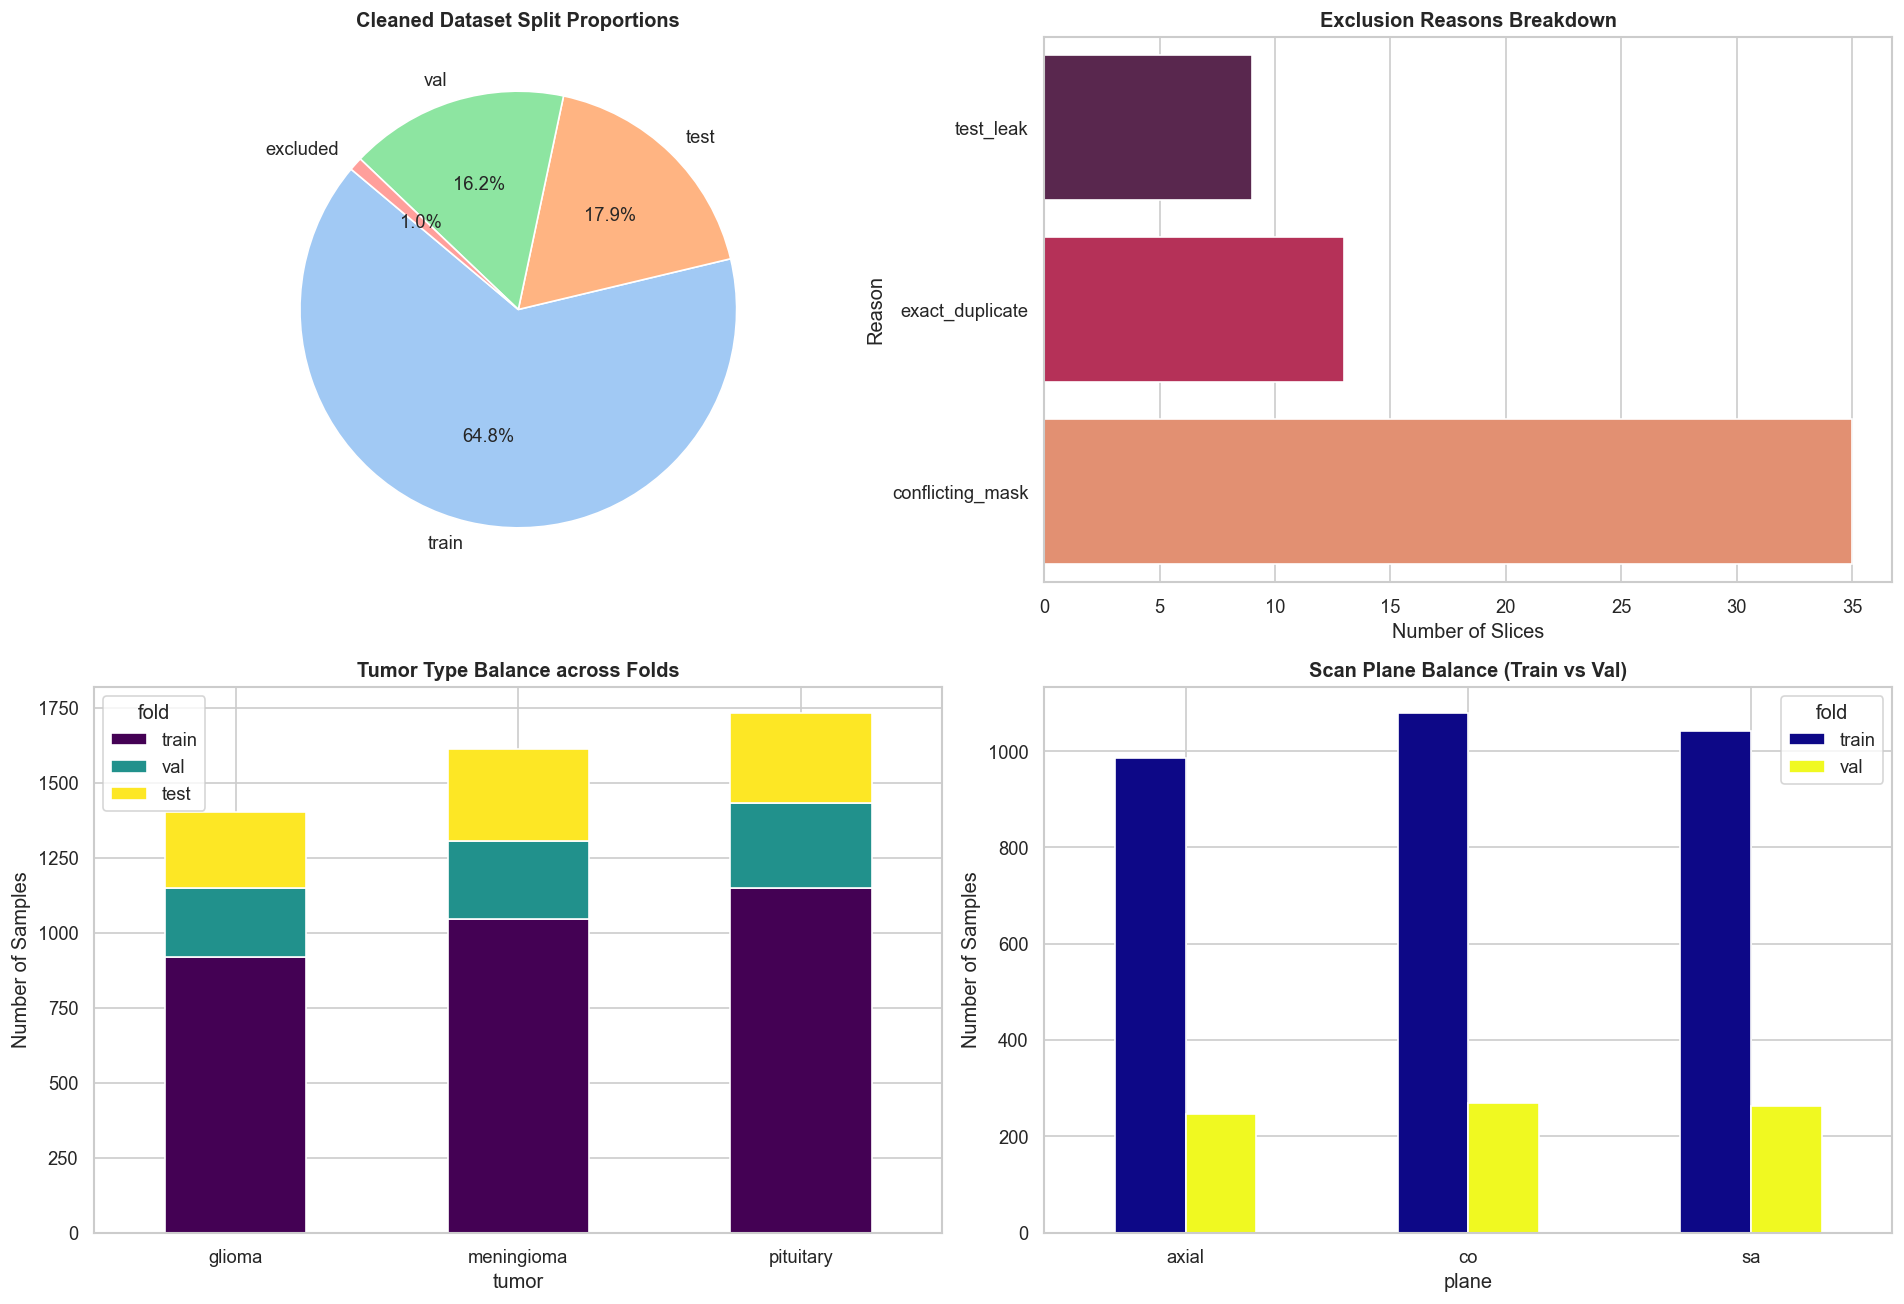

In [13]:
# 13. Cleaning Analytics Dashboard
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# A. Fold Distribution
fold_counts = manifest_df['fold'].value_counts()
axes[0, 0].pie(fold_counts, labels=fold_counts.index, autopct='%1.1f%%', colors=sns.color_palette('pastel'), startangle=140)
axes[0, 0].set_title('Cleaned Dataset Split Proportions', fontweight='bold')

# B. Exclusion Reasons Breakdown
if exclusions_by_reason:
    ex_df = pd.DataFrame(list(exclusions_by_reason.items()), columns=['Reason', 'Count']).sort_values('Count', ascending=True)
    sns.barplot(data=ex_df, y='Reason', x='Count', ax=axes[0, 1], palette='rocket')
    axes[0, 1].set_title('Exclusion Reasons Breakdown', fontweight='bold')
    axes[0, 1].set_xlabel('Number of Slices')

# C. Tumor Class Stratification across Folds
crosstab = pd.crosstab(manifest_df[manifest_df['fold'].isin(['train', 'val', 'test'])]['tumor'], manifest_df['fold'])
crosstab[['train', 'val', 'test']].plot(kind='bar', stacked=True, ax=axes[1, 0], colormap='viridis')
axes[1, 0].set_title('Tumor Type Balance across Folds', fontweight='bold')
axes[1, 0].set_ylabel('Number of Samples')
axes[1, 0].tick_params(axis='x', rotation=0)

# D. Scan Plane Balance
crosstab_plane = pd.crosstab(manifest_df[manifest_df['fold'].isin(['train', 'val'])]['plane'], manifest_df['fold'])
crosstab_plane[['train', 'val']].plot(kind='bar', ax=axes[1, 1], colormap='plasma')
axes[1, 1].set_title('Scan Plane Balance (Train vs Val)', fontweight='bold')
axes[1, 1].set_ylabel('Number of Samples')
axes[1, 1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

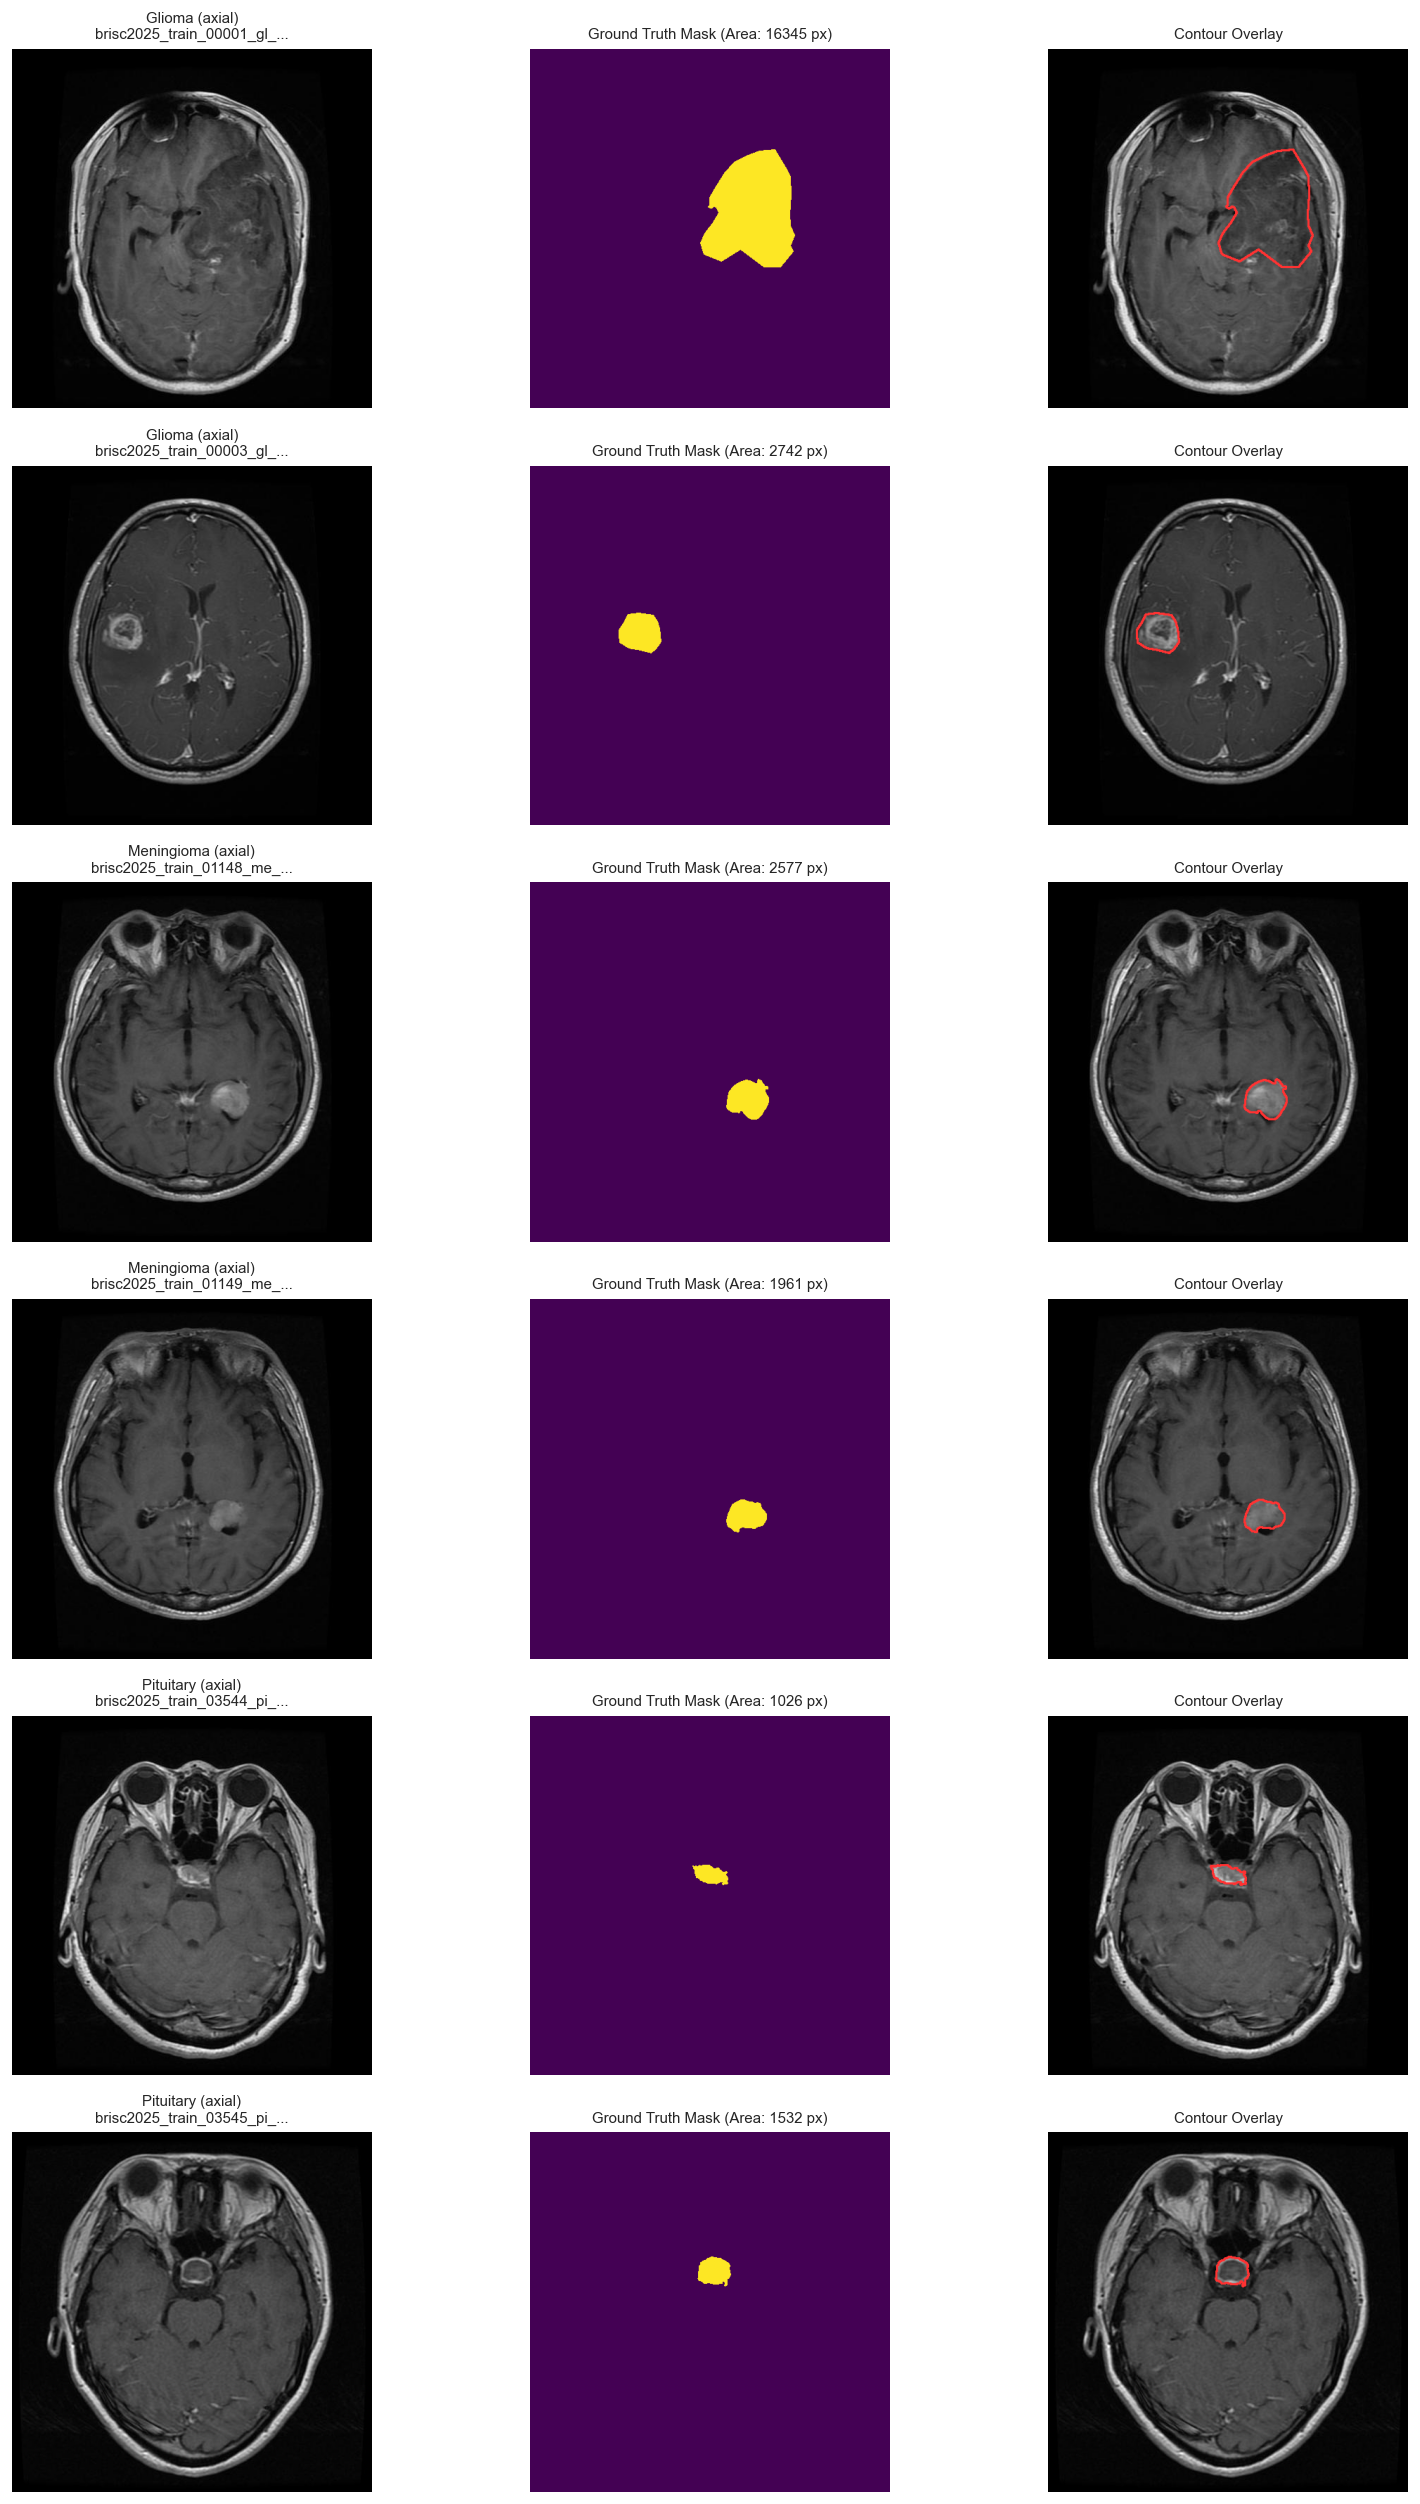

In [14]:
# 14. Representative Gallery of Cleaned Samples
clean_samples = manifest_df[manifest_df['fold'] == 'train'].groupby('tumor').head(2)

fig, axes = plt.subplots(len(clean_samples), 3, figsize=(14, 3.5 * len(clean_samples)))

for idx, (_, row) in enumerate(clean_samples.iterrows()):
    img_path = seg_df[seg_df['stem'] == row['stem']]['image_path'].iloc[0]
    mask_path = seg_df[seg_df['stem'] == row['stem']]['mask_path'].iloc[0]
    
    img = np.array(Image.open(img_path).convert('RGB'))
    mask = np.array(Image.open(mask_path).convert('L')) > 127
    
    # Overlay contour
    overlay = img.copy()
    contours, _ = cv2.findContours(mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(overlay, contours, -1, (255, 50, 50), 2)
    
    axes[idx, 0].imshow(img)
    axes[idx, 0].set_title(f"{row['tumor'].capitalize()} ({row['plane']})\n{row['stem'][:25]}...", fontsize=9)
    axes[idx, 0].axis('off')
    
    axes[idx, 1].imshow(mask, cmap='viridis')
    axes[idx, 1].set_title(f"Ground Truth Mask (Area: {int(row['tumor_pixels'])} px)", fontsize=9)
    axes[idx, 1].axis('off')
    
    axes[idx, 2].imshow(overlay)
    axes[idx, 2].set_title("Contour Overlay", fontsize=9)
    axes[idx, 2].axis('off')

plt.tight_layout()
plt.show()

## 9. Manifest Export

We export `clean_manifest.csv` directly into the `notebooks/` directory alongside this notebook, making it immediately available for downstream training pipelines (`AttentionUnet.ipynb`, `SwinUNETR.ipynb`, `classification.ipynb`).

In [15]:
# 15. Export Clean Manifest to Notebooks Directory
notebook_dir = Path("notebooks") if Path("notebooks").exists() else Path(".")
out_path = notebook_dir / "clean_manifest.csv"

out_path.parent.mkdir(parents=True, exist_ok=True)
manifest_df.to_csv(out_path, index=False)

print(f"✓ Successfully exported clean manifest")

✓ Successfully exported clean manifest
